<a href="https://colab.research.google.com/github/JeissonR115/CNN/blob/main/notebooks/entrenamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN: exploración, entrenamiento y evaluación

Este notebook usa los módulos versionados del repositorio y lee CIFAR-10 directamente desde `data/cifar-10-batches-py/`. También acepta carpetas de imágenes etiquetadas. CIFAR-10 conserva sus cinco lotes de entrenamiento para crear train/validation y reserva el `test_batch` oficial para la evaluación final. El entrenamiento guarda los artefactos en `models/`; esos archivos son locales y están ignorados por Git.

### Ejecutar en Google Colab

1. En Colab, selecciona **Runtime → Change runtime type** y elige una GPU en **Hardware accelerator** si está disponible.
2. Ejecuta la primera celda de código. Detectará Colab, clonará el repositorio, instalará `requirements.txt` y descargará CIFAR-10 si todavía no está en `data/`.
3. Ejecuta las demás celdas en orden. Para limitar el entrenamiento, establece `CNN_TRAINING_EPOCHS` en `1` o `3` antes de la celda de entrenamiento. La GPU gratuita puede no estar disponible en todas las sesiones.

En Colab el disco es temporal; al final puedes descargar los artefactos del modelo con la última sección. Desde VS Code o Jupyter local, la primera celda detecta el repositorio y usa los datos locales sin clonar ni descargar automáticamente.

TensorFlow: 2.21.0
Keras: 3.15.1
GPU detectada por TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Fuente: CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz
Raíz medida: /content/CNN/data/cifar-10-batches-py
Clases con imágenes legibles: 10
Validación del rango 3-10: válida
Imágenes etiquetadas legibles: 60000

Imágenes por partición y clase (solo archivos decodificables):
- data_batch_1: airplane=1005, automobile=974, bird=1032, cat=1016, deer=999, dog=937, frog=1030, horse=1001, ship=1025, truck=981 (total=10000)
- data_batch_2: airplane=984, automobile=1007, bird=1010, cat=995, deer=1010, dog=988, frog=1008, horse=1026, ship=987, truck=985 (total=10000)
- data_batch_3: airplane=994, automobile=1042, bird=965, cat=997, deer=990, dog=1029, frog=978, horse=1015, ship=961, truck=1029 (total=10000)
- data_batch_4: airplane=1003, automobile=963, bird=1041, cat=976, deer=1004, dog=1021, frog=1004, horse=981, ship=1024, truck=983 (total=10000)


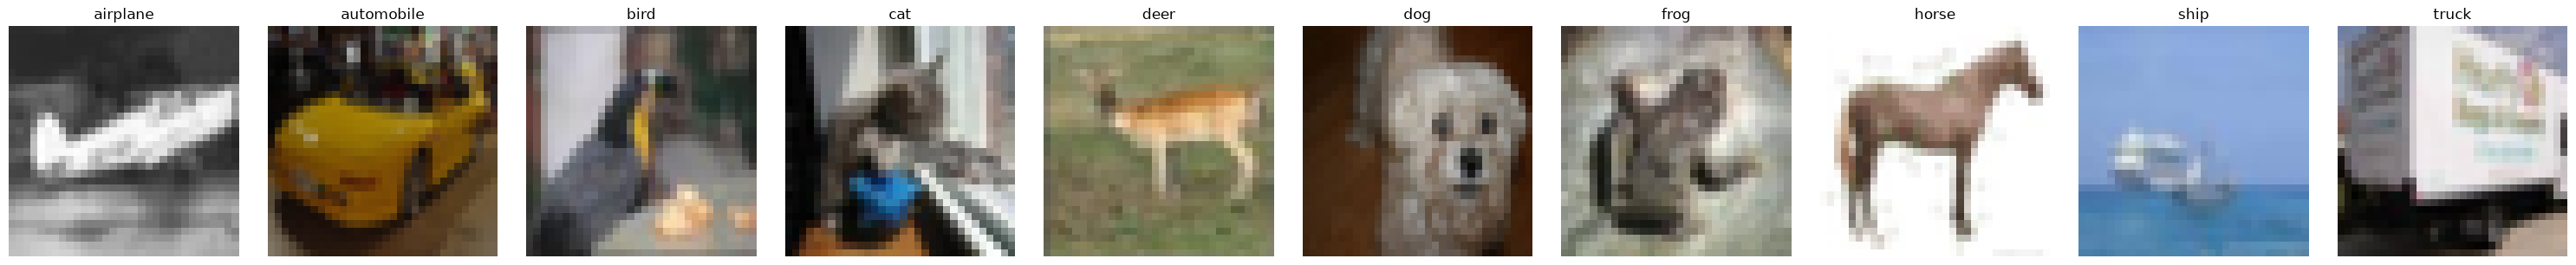

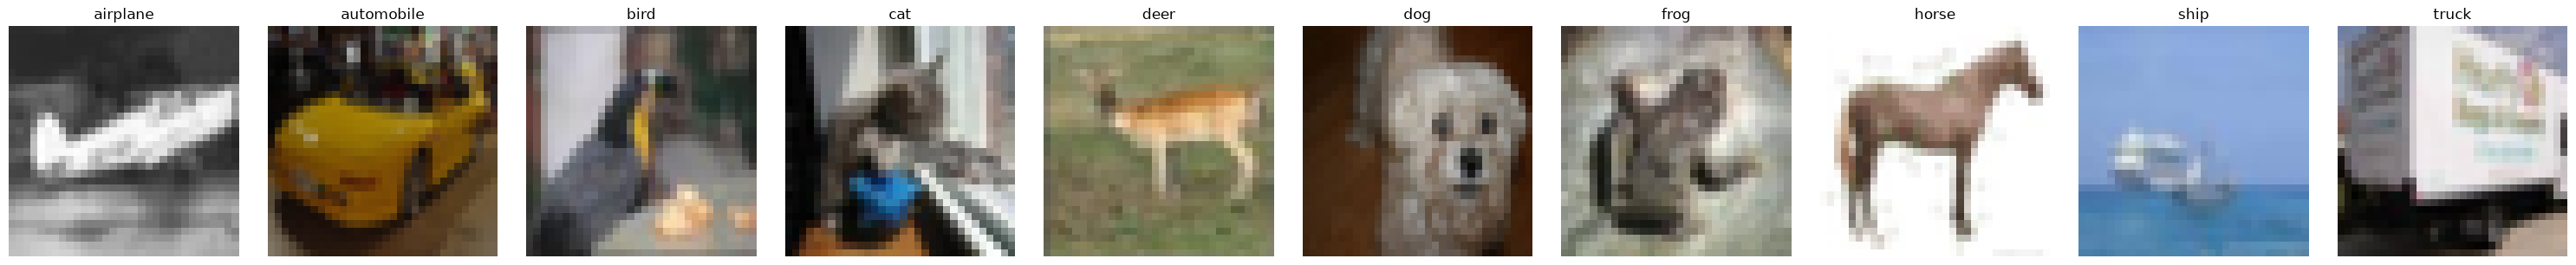

In [4]:
import os
import subprocess
import sys
import tarfile
import urllib.request
from pathlib import Path

# ============================================================
# DETECTAR ENTORNO GOOGLE COLAB
# ============================================================

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


# ============================================================
# LOCALIZAR O CLONAR EL PROYECTO
# ============================================================

project_candidates = (Path.cwd(), *Path.cwd().parents)

PROJECT_ROOT = next(
    (
        path
        for path in project_candidates
        if (path / "src").is_dir()
        and (path / "requirements.txt").is_file()
    ),
    None,
)

if IN_COLAB and (
    PROJECT_ROOT is None or PROJECT_ROOT == Path("/content/CNN")
):
    PROJECT_ROOT = Path("/content/CNN")

    if not PROJECT_ROOT.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "https://github.com/JeissonR115/CNN.git",
                str(PROJECT_ROOT),
            ],
            check=True,
        )
    else:
        update = subprocess.run(
            ["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"],
            capture_output=True,
            text=True,
            check=False,
        )

        if update.returncode:
            raise RuntimeError(
                "No se pudo actualizar el clon de GitHub:\n"
                f"{update.stdout}\n{update.stderr}"
            )


if PROJECT_ROOT is None or not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        "No se encontró el repositorio con src/ y requirements.txt."
    )


# ============================================================
# INSTALAR DEPENDENCIAS
# ============================================================

if IN_COLAB:
    installation = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-r",
            str(PROJECT_ROOT / "requirements.txt"),
        ],
        capture_output=True,
        text=True,
        check=False,
    )

    if installation.returncode:
        details = "\n".join(
            (installation.stdout + "\n" + installation.stderr).splitlines()[-80:]
        )

        raise RuntimeError(
            "Falló la instalación de requirements.txt. "
            f"Últimas líneas de pip:\n{details}"
        )


# ============================================================
# CONFIGURAR NUMPY
# ============================================================

import numpy as np

# Compatibilidad con librerías que utilizan esta función
if not hasattr(np, "_no_nep50_warning"):

    def _dummy_decorator(*args, **kwargs):
        def decorator(func):
            return func
        return decorator

    np._no_nep50_warning = _dummy_decorator


# ============================================================
# CONFIGURAR RUTA DEL PROYECTO
# ============================================================

os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# ============================================================
# CONFIGURAR DATASET CIFAR-10
# ============================================================

DATASET_OVERRIDE = os.environ.get("CNN_DATASET_DIR")

DATASET_DIR = Path(
    DATASET_OVERRIDE or "data/cifar-10-batches-py"
).expanduser()

if not DATASET_DIR.is_absolute():
    DATASET_DIR = PROJECT_ROOT / DATASET_DIR


# ============================================================
# DESCARGAR DATASET SI NO EXISTE
# ============================================================

if (
    IN_COLAB
    and DATASET_OVERRIDE is None
    and not (DATASET_DIR / "batches.meta").is_file()
):
    data_directory = PROJECT_ROOT / "data"

    archive_path = data_directory / "cifar-10-python.tar.gz"

    data_directory.mkdir(parents=True, exist_ok=True)

    print("Descargando dataset CIFAR-10...")

    urllib.request.urlretrieve(
        "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz",
        archive_path,
    )

    with tarfile.open(archive_path, "r:gz") as archive:
        archive.extractall(data_directory)

    print("Dataset descargado y extraído correctamente.")


# ============================================================
# IMPORTAR HERRAMIENTAS DE EXPLORACIÓN
# ============================================================

import matplotlib.pyplot as plt

from IPython.display import display

from src.exploration import (
    explore_dataset,
    plot_examples,
    read_record_image,
)


# ============================================================
# VERIFICAR TENSORFLOW Y GPU
# ============================================================

if IN_COLAB:
    import tensorflow as tf

    print("TensorFlow:", tf.__version__)
    print("Keras:", tf.keras.__version__)

    print(
        "GPU detectada por TensorFlow:",
        tf.config.list_physical_devices("GPU"),
    )


# ============================================================
# EXPLORAR DATASET
# ============================================================

try:
    report = explore_dataset(DATASET_DIR)

except FileNotFoundError as error:
    print(f"BLOQUEADO: {error}")
    DATASET_AVAILABLE = False

else:
    print(report.summary())

    DATASET_AVAILABLE = report.class_count_valid

    if DATASET_AVAILABLE:
        display(plot_examples(report))
    else:
        print("BLOQUEADO: corrige el dataset antes de entrenar.")

## Preparación y preprocesamiento

Para CIFAR-10, los cinco lotes `data_batch_1`–`data_batch_5` se separan estratificadamente en 85 % train y 15 % validation. El `test_batch` oficial se mantiene intacto como test, sin participar en el entrenamiento. Para otros datasets organizados en carpetas, se usa una división estratificada 70/15/15. Cada imagen se convierte a RGB, se conserva a 32 × 32 y se convierte a `float32` en `[0, 1]` dividiendo cada canal de 8 bits por 255. La predicción reutiliza exactamente `preprocess_image`.

In [3]:
# Parcheamos de forma robusta la configuración de SciPy directamente en el sistema de módulos
import sys
import scipy

try:
    # Accedemos a la configuración interna de SciPy
    import scipy.__config__ as scipy_config
    # Aseguramos que existan las dependencias de compilación esperadas para evitar KeyError tanto en blas como en lapack
    if "Build Dependencies" not in scipy_config.CONFIG:
        scipy_config.CONFIG["Build Dependencies"] = {}

    build_deps = scipy_config.CONFIG["Build Dependencies"]

    if "blas" not in build_deps:
        build_deps["blas"] = {"cython blas ilp64": False, "has ilp64": False}
    else:
        build_deps["blas"]["cython blas ilp64"] = build_deps["blas"].get("cython blas ilp64", False)
        build_deps["blas"]["has ilp64"] = build_deps["blas"].get("has ilp64", False)

    if "lapack" not in build_deps:
        build_deps["lapack"] = {"cython lapack ilp64": False, "has ilp64": False}
    else:
        build_deps["lapack"]["cython lapack ilp64"] = build_deps["lapack"].get("cython lapack ilp64", False)
        build_deps["lapack"]["has ilp64"] = build_deps["lapack"].get("has ilp64", False)
except Exception:
    pass

# Aseguramos compatibilidad de NumPy también
import numpy as np
if not hasattr(np, "_no_nep50_warning"):
    def _dummy_decorator(*args, **kwargs):
        def decorator(func):
            return func
        return decorator
    np._no_nep50_warning = _dummy_decorator

from src.data import load_labeled_records, split_dataset

if DATASET_AVAILABLE:
    records = load_labeled_records(DATASET_DIR)
    splits = split_dataset(records)
    class_names = splits.class_names
    print(f"Clases (orden de salida): {class_names}")
    print(
        f"Train: {len(splits.train)} | Validation: {len(splits.validation)} | "
        f"Test: {len(splits.test)}"
    )
else:
    print("BLOQUEADO: configura un dataset legible antes de continuar.")

Clases (orden de salida): ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
Train: 42500 | Validation: 7500 | Test: 10000


## Vista previa de aumentación

La aumentación se aplica en línea solo después de la división y solo a train: flip horizontal (probabilidad 0,5), rotación ±15°, zoom ±10 % y contraste 0,8–1,2. Validation, test y predicción usan únicamente el preprocesamiento base. La cuadrícula selecciona una muestra train por clase y fija las semillas para que se pueda revisar el mismo ejemplo y los mismos efectos.

TensorFlow: 2.21.0
Keras: 3.15.1
KerasTensor disponible: True


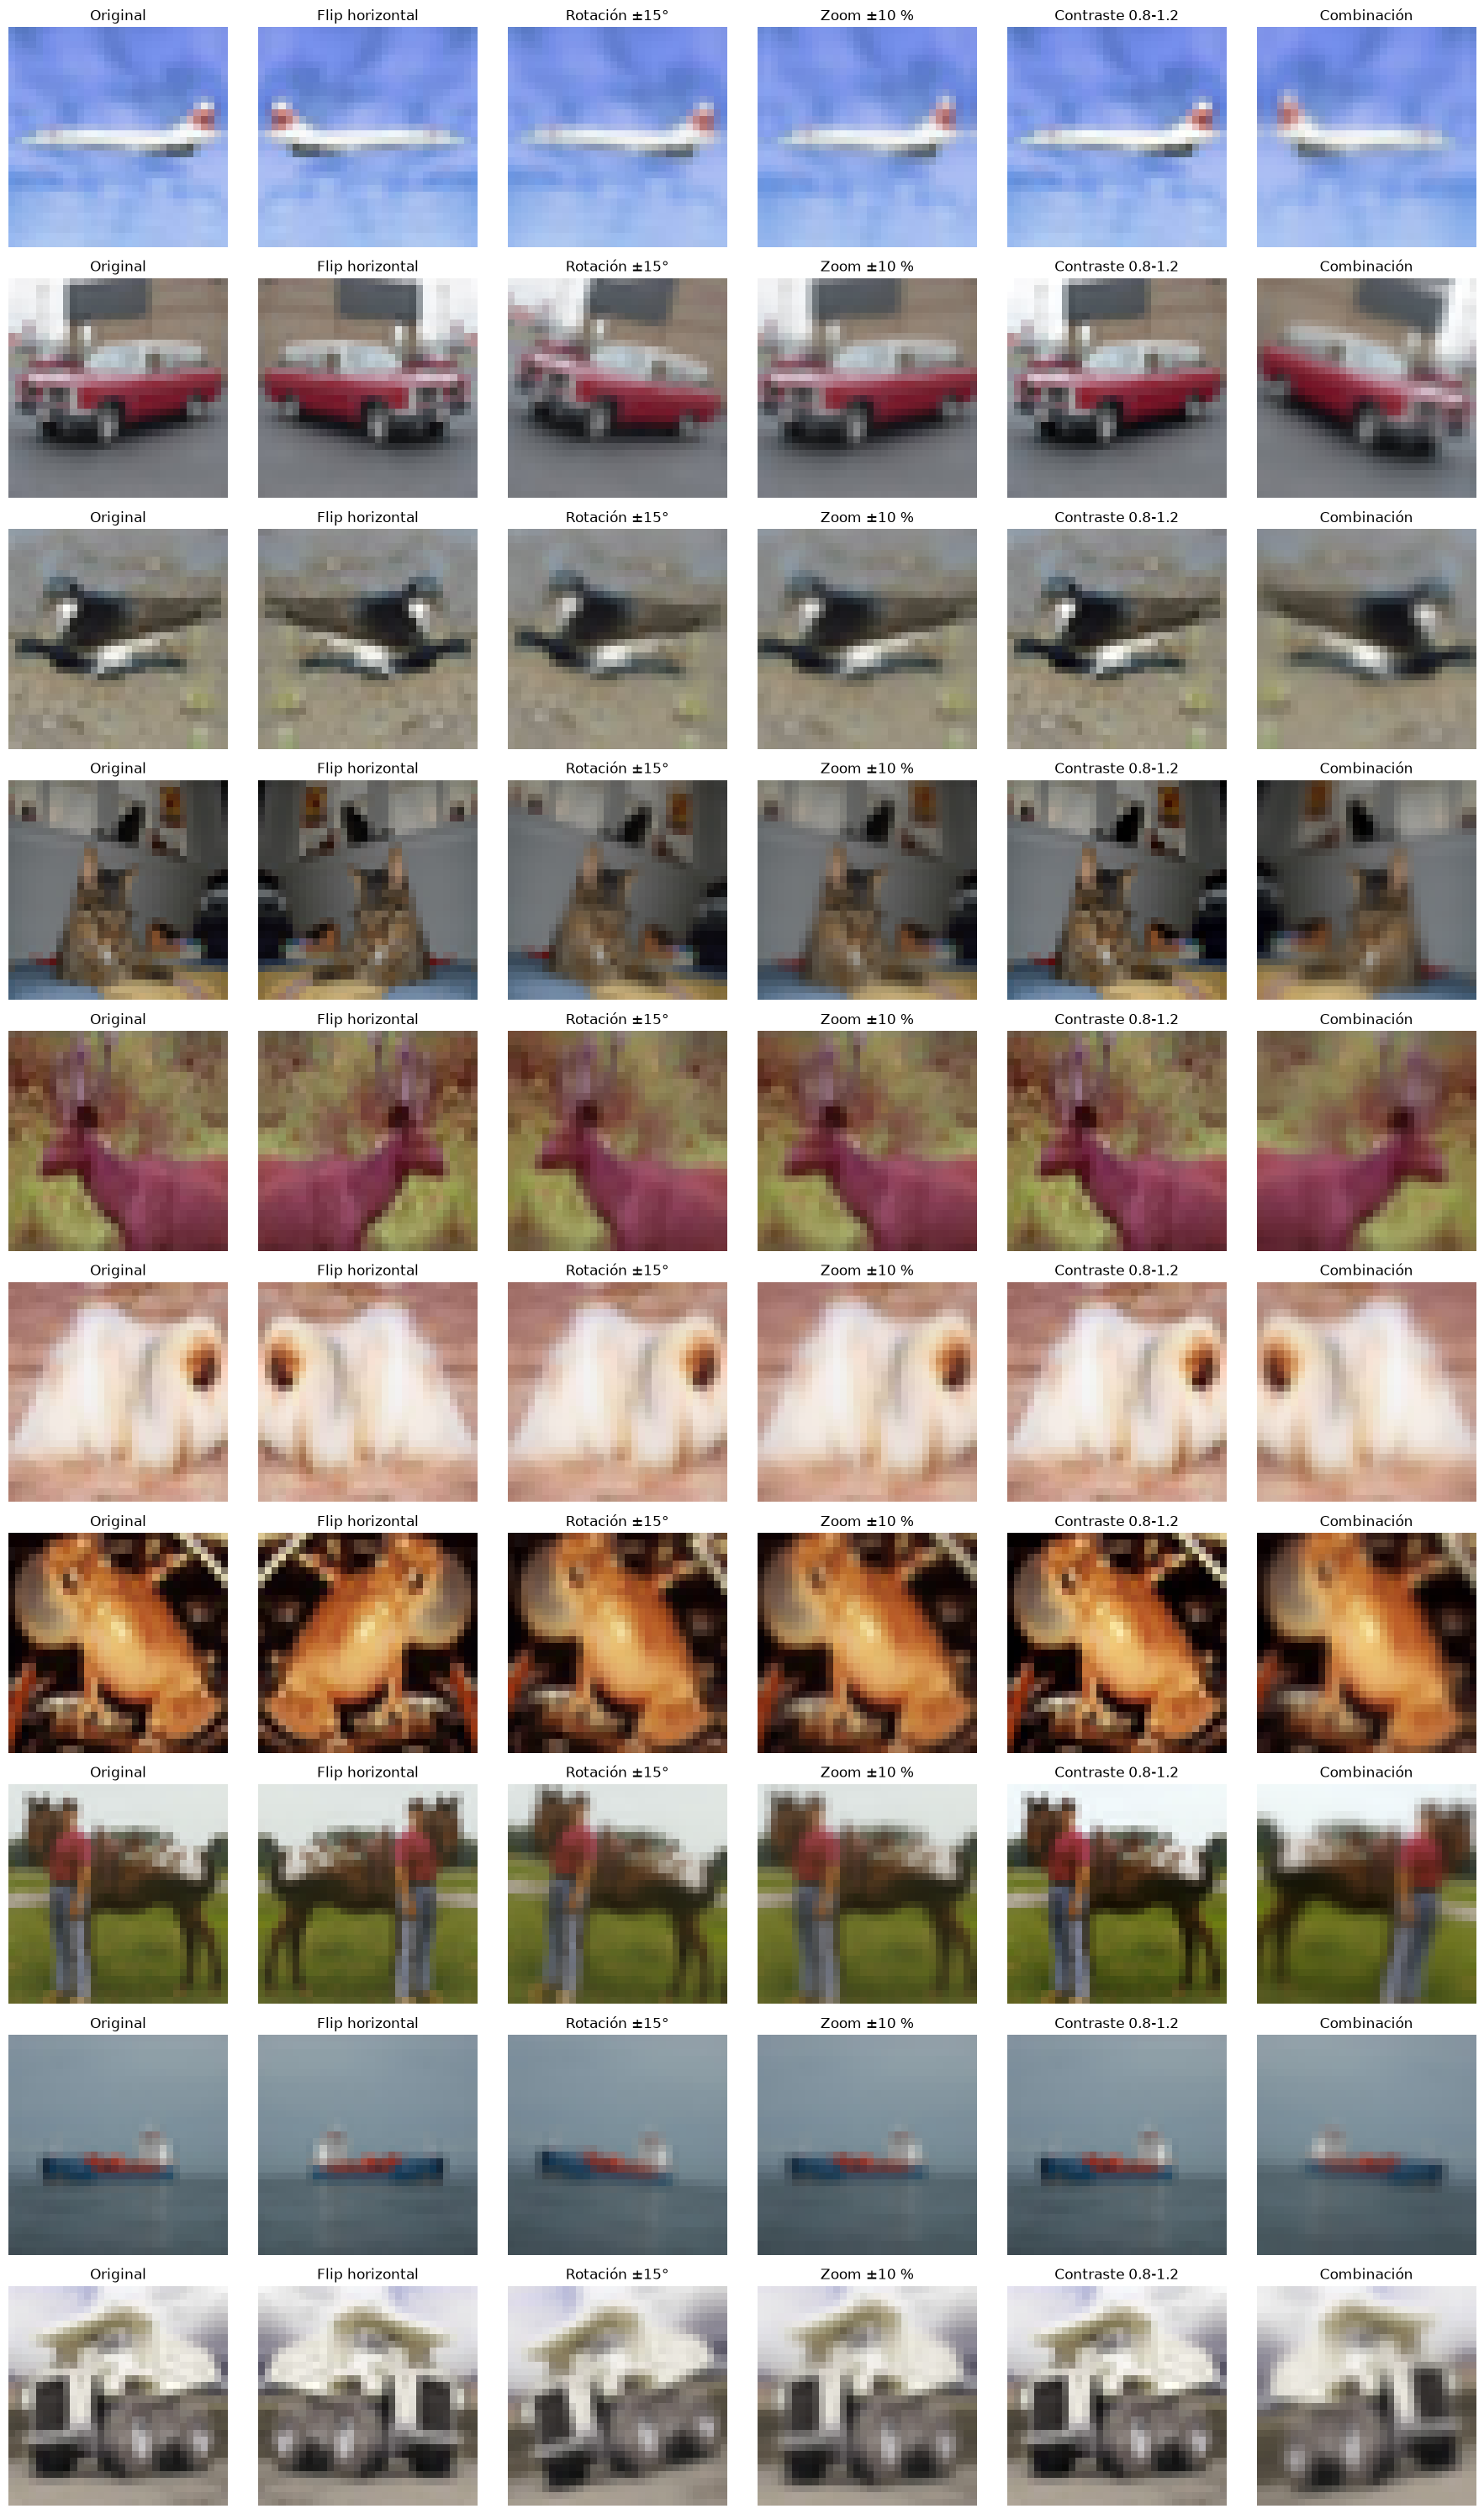

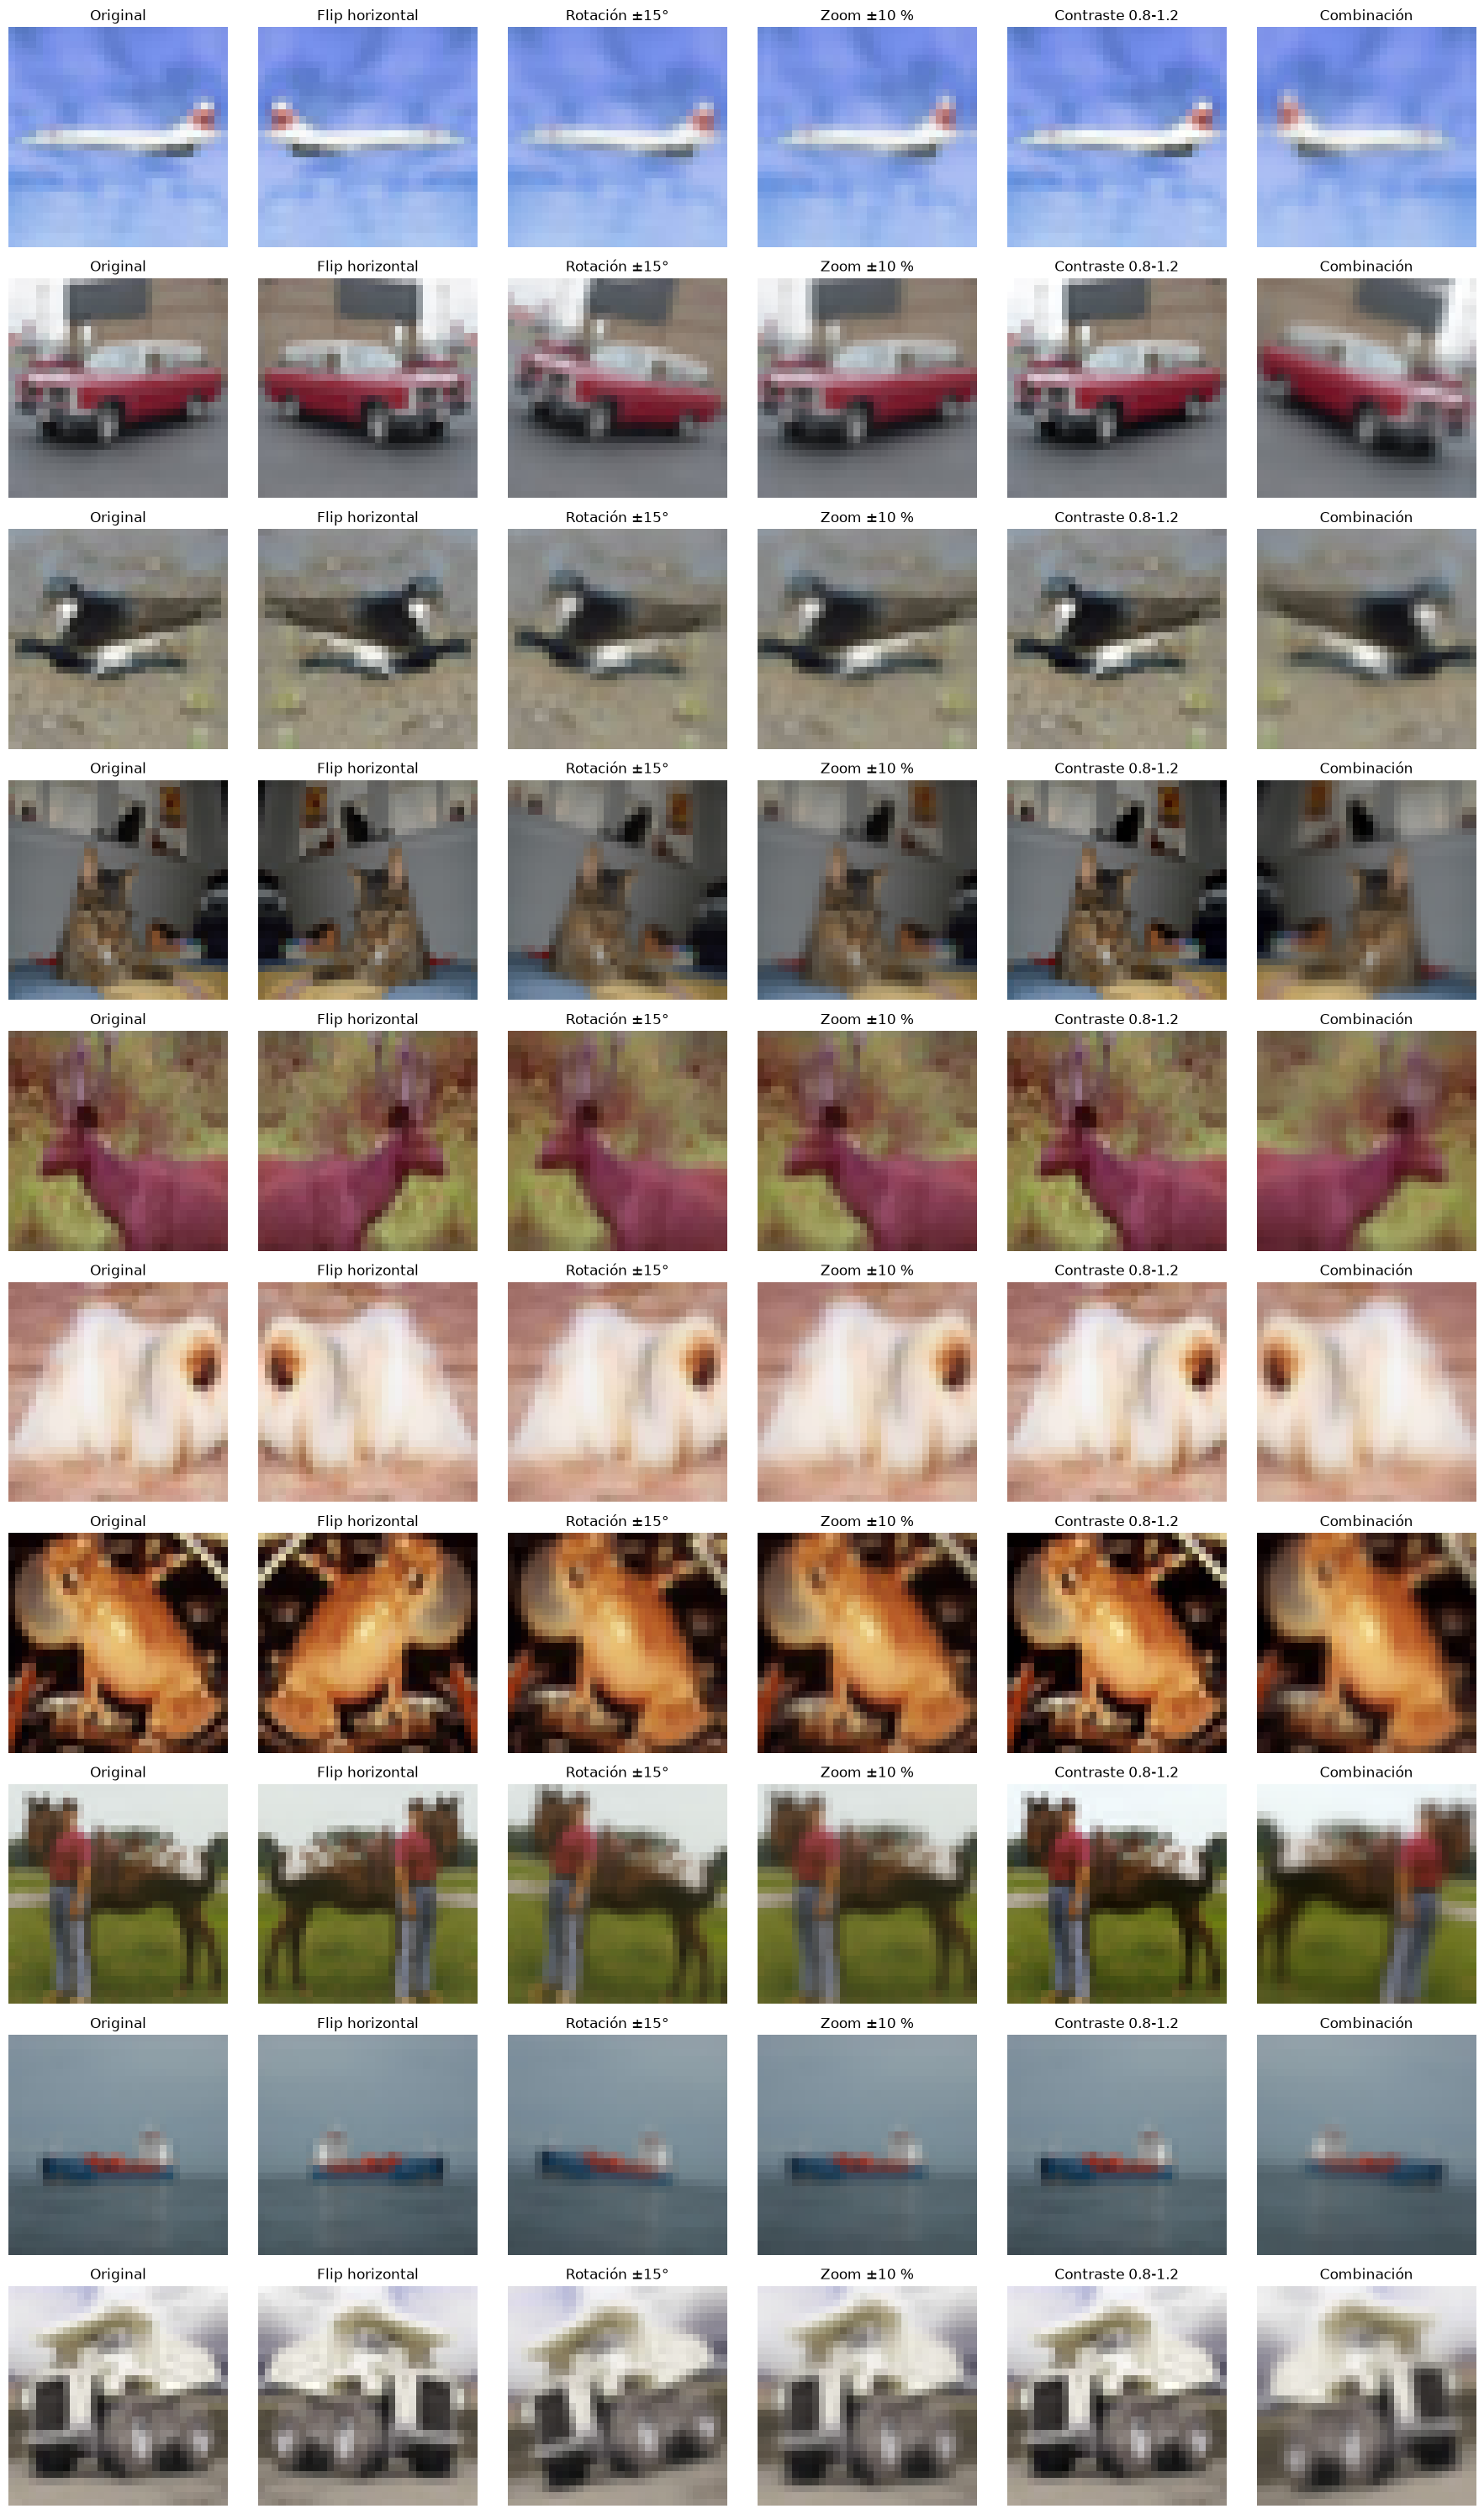

In [5]:
# ============================================================
# VISTA PREVIA DE DATA AUGMENTATION
# ============================================================

import tensorflow as tf
import keras

from src.data import plot_augmentation_examples

# Verificar versiones y compatibilidad
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasTensor disponible:", hasattr(keras, "KerasTensor"))

# Generar vista previa
if DATASET_AVAILABLE:
    display(
        plot_augmentation_examples(
            splits.train,
            class_names,
            seed=42
        )
    )
else:
    print("BLOQUEADO: la vista previa requiere las particiones train.")

## Arquitectura y entrenamiento

La CNN recibe tensores 32 × 32 × 3 y usa tres bloques Conv2D + MaxPooling2D (32, 64 y 128 filtros), seguidos de Flatten, Dense(128), Dropout(0,5) y softmax con una salida por clase. Esta arquitectura ligera está pensada para CIFAR-10 y reduce el tiempo de entrenamiento. Se compila con Adam (0,001), sparse categorical crossentropy y accuracy; el ajuste usa lotes de 32 y hasta 30 épocas (2 por defecto; `CNN_TRAINING_EPOCHS` permite cambiarlo). `model.summary()` se imprime antes de `fit`.

EarlyStopping y ReduceLROnPlateau monitorizan `val_loss`; ModelCheckpoint conserva únicamente el mejor checkpoint por `val_loss`. El conjunto test no se usa para entrenamiento ni callbacks. Al terminar se recarga y verifica el modelo guardado y su lista ordenada de clases.

In [6]:
from src.train import train

TRAINING_EPOCHS = int(os.environ.get("CNN_TRAINING_EPOCHS", "2"))
if not 1 <= TRAINING_EPOCHS <= 30:
    raise ValueError("CNN_TRAINING_EPOCHS must be between 1 and 30.")

if DATASET_AVAILABLE:
    model, history, class_names = train(DATASET_DIR, epochs=TRAINING_EPOCHS)
    print(f"Modelo verificado: {PROJECT_ROOT / 'models/cnn_classifier.keras'}")
    print(f"Clases guardadas: {PROJECT_ROOT / 'models/class_names.json'}")
else:
    print("BLOQUEADO: no se inició el entrenamiento.")

Model: "cnn_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_dropout (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 92s 62ms/step - accuracy: 0.3772 - loss: 1.6935 - val_accuracy: 0.5343 - val_loss: 1.3009 - learning_rate: 0.0010
Epoch 2/2
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 75s 56ms/step - accuracy: 0.5152 - loss: 1.3550 - val_accuracy: 0.6097 - val_loss: 1.1210 - learning_rate: 0.0010
Modelo verificado: /content/CNN/models/cnn_classifier.keras
Clases guardadas: /content/CNN/models/class_names.json


## Curvas de entrenamiento

Las series requeridas se validan explícitamente antes de graficar; una serie ausente es un error y no se presenta como un resultado completo.

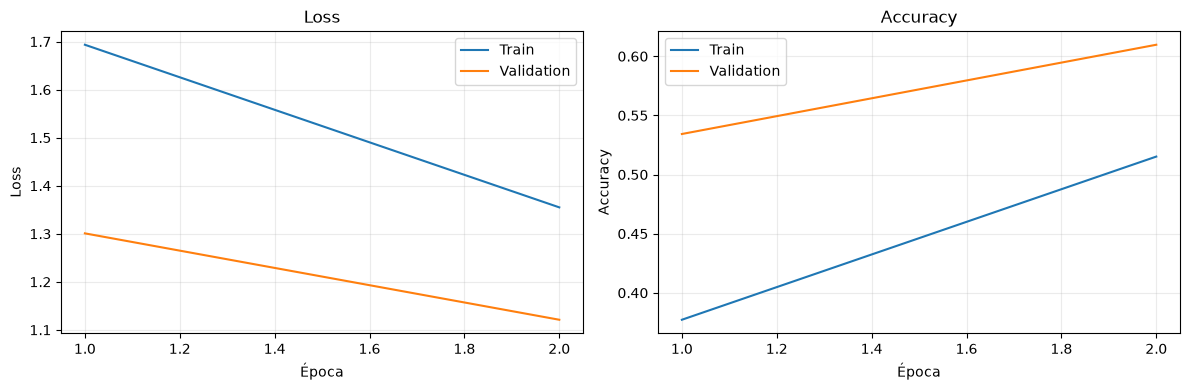

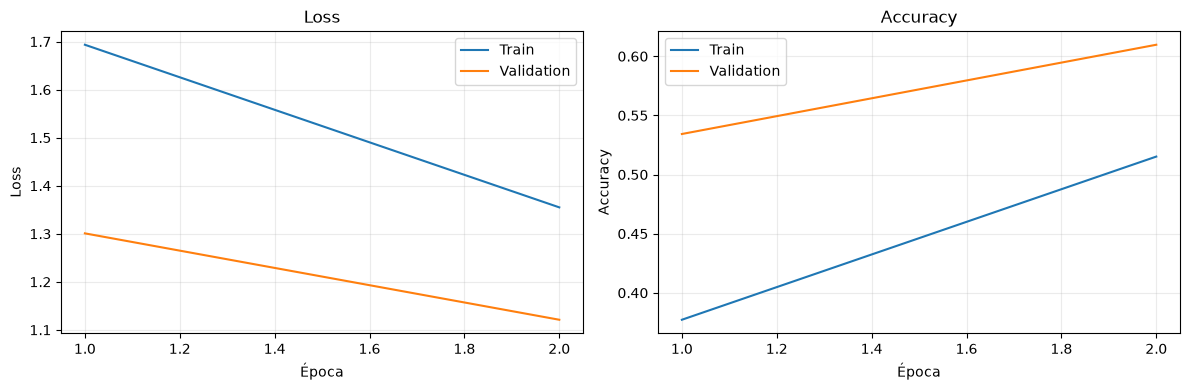

In [7]:
if DATASET_AVAILABLE:
    required_history = ("loss", "val_loss", "accuracy", "val_accuracy")
    missing_history = [name for name in required_history if name not in history.history]
    if missing_history:
        raise ValueError(f"El historial no contiene las series: {missing_history}")

    epochs = np.arange(1, len(history.history["loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history.history["loss"], label="Train")
    axes[0].plot(epochs, history.history["val_loss"], label="Validation")
    axes[0].set(title="Loss", xlabel="Época", ylabel="Loss")
    axes[1].plot(epochs, history.history["accuracy"], label="Train")
    axes[1].plot(epochs, history.history["val_accuracy"], label="Validation")
    axes[1].set(title="Accuracy", xlabel="Época", ylabel="Accuracy")
    for axis in axes:
        axis.legend()
        axis.grid(True, alpha=0.25)
    figure.tight_layout()
    display(figure)
else:
    print("BLOQUEADO: las curvas requieren un historial de entrenamiento.")

## Evaluación final en test

Esta sección se ejecuta después de finalizar el ajuste y seleccionar el checkpoint mediante validation. Calcula métricas sobre todo test y usa el mismo orden de clases guardado con el modelo. Si el conjunto estuviera vacío, no se inventan métricas.

Test accuracy: 0.6101
              precision    recall  f1-score   support

    airplane       0.63      0.69      0.66      1000
  automobile       0.64      0.82      0.72      1000
        bird       0.53      0.44      0.48      1000
         cat       0.47      0.37      0.41      1000
        deer       0.64      0.39      0.48      1000
         dog       0.49      0.55      0.52      1000
        frog       0.67      0.73      0.70      1000
       horse       0.65      0.71      0.68      1000
        ship       0.78      0.69      0.73      1000
       truck       0.58      0.72      0.64      1000

    accuracy                           0.61     10000
   macro avg       0.61      0.61      0.60     10000
weighted avg       0.61      0.61      0.60     10000



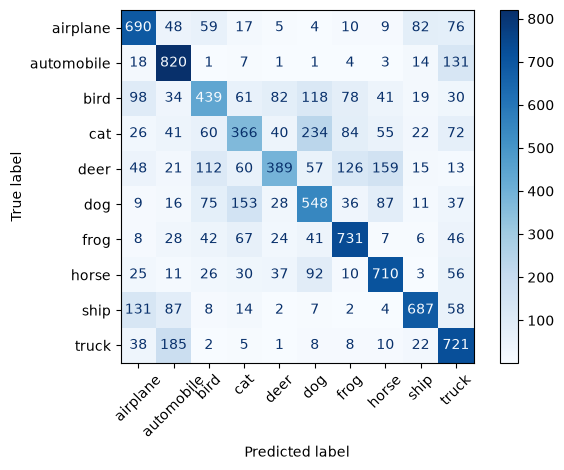

In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from src.data import make_dataset

if DATASET_AVAILABLE:
    if not splits.test:
        print("BLOQUEADO: no hay ejemplos etiquetados en test para evaluar.")
        test_probabilities = np.empty((0, len(class_names)), dtype=np.float32)
        test_labels = np.empty((0,), dtype=np.int32)
    else:
        test_data = make_dataset(splits.test, class_names, batch_size=32)
        test_labels = np.asarray(
            [class_names.index(record.class_name) for record in splits.test],
            dtype=np.int32,
        )
        test_probabilities = model.predict(test_data, verbose=0)
        test_predictions = np.argmax(test_probabilities, axis=1)
        class_indices = np.arange(len(class_names))
        print(f"Test accuracy: {accuracy_score(test_labels, test_predictions):.4f}")
        print(
            classification_report(
                test_labels,
                test_predictions,
                labels=class_indices,
                target_names=class_names,
                zero_division=0,
            )
        )
        matrix = confusion_matrix(
            test_labels, test_predictions, labels=class_indices
        )
        confusion_display = ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=class_names
        )
        confusion_display.plot(xticks_rotation=45, cmap="Blues", values_format="d")
        plt.tight_layout()
        plt.show()

## Predicciones individuales

Se seleccionan hasta 10 ejemplos distintos de test sin reemplazo, de forma reproducible con semilla 42. Se informa la clase real, la predicha y la probabilidad de la clase predicha. Si hay entre 1 y 9 imágenes, se muestran todas y se advierte que no se alcanzó el mínimo.

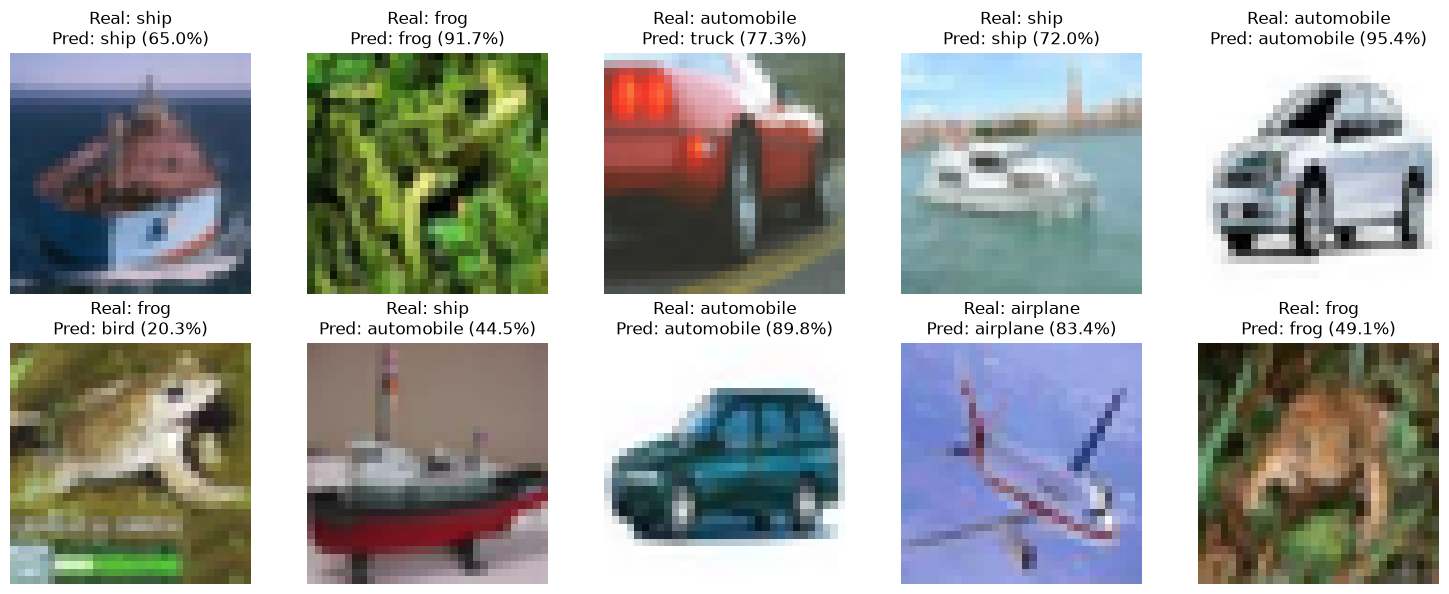

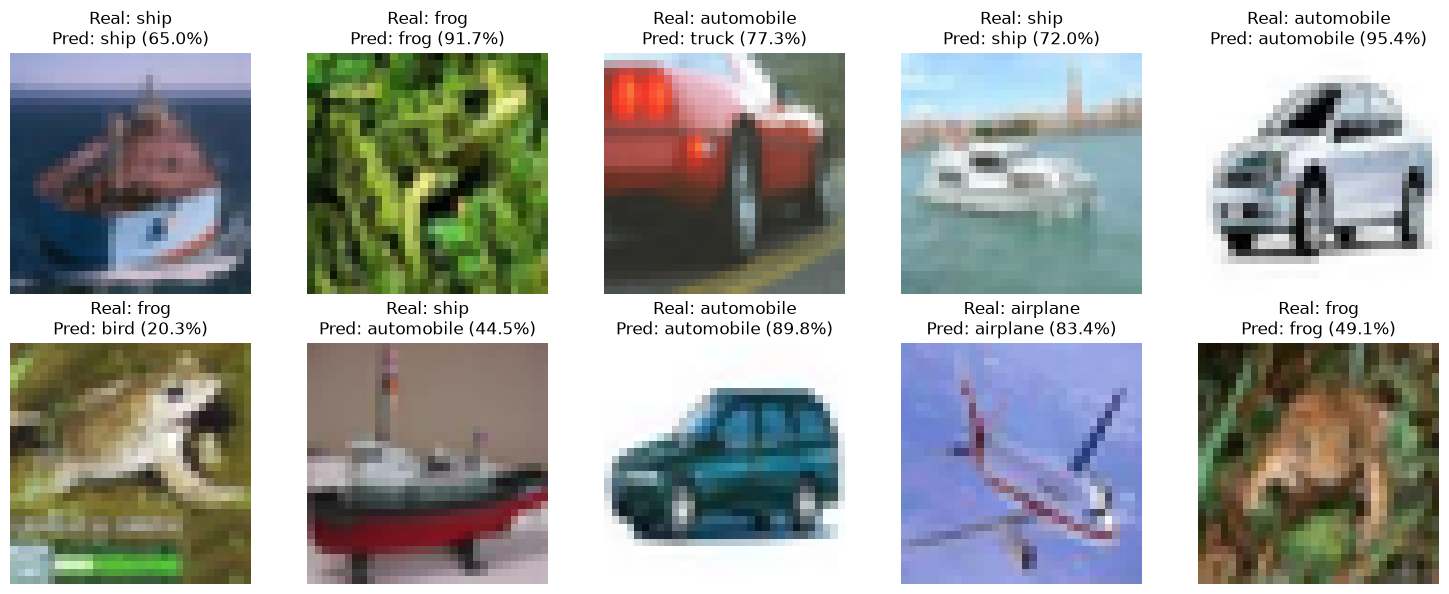

In [9]:
if DATASET_AVAILABLE and len(splits.test):
    if len(splits.test) < 10:
        print(
            f"Advertencia: test contiene {len(splits.test)} ejemplo(s); "
            "no se alcanzó el mínimo de 10. Se muestran todos."
        )
    sample_count = min(10, len(splits.test))
    selected_indices = np.sort(
        np.random.default_rng(42).choice(
            len(splits.test), size=sample_count, replace=False
        )
    )
    columns = min(5, sample_count)
    rows = int(np.ceil(sample_count / columns))
    figure, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows), squeeze=False)
    from src.exploration import read_record_image
    for axis, index in zip(axes.flat, selected_indices):
        record = splits.test[int(index)]
        predicted_index = int(np.argmax(test_probabilities[index]))
        confidence = float(test_probabilities[index, predicted_index])
        axis.imshow(read_record_image(record))
        axis.set_title(
            f"Real: {record.class_name}\nPred: {class_names[predicted_index]} "
            f"({confidence:.1%})"
        )
        axis.axis("off")
    for axis in axes.flat[sample_count:]:
        axis.axis("off")
    figure.tight_layout()
    display(figure)
elif DATASET_AVAILABLE:
    print("BLOQUEADO: no hay predicciones individuales para mostrar.")

## Predicción con la API compartida

`src.predict.predict` carga los artefactos guardados, aplica el mismo preprocesamiento y devuelve `(nombre_de_clase, confianza)`. Esta llamada de ejemplo usa una imagen del dataset; la aplicación Streamlit consume la misma API.

In [10]:
from src.predict import predict

if DATASET_AVAILABLE and splits.test:
    print(predict(read_record_image(splits.test[0])))
else:
    print("BLOQUEADO: la predicción requiere los artefactos entrenados y una imagen.")

('cat', 0.5121862292289734)


## Descargar el modelo desde Colab (opcional)

Ejecuta esta celda después de entrenar si quieres guardar los artefactos en tu computadora. En Colab se descargarán el modelo y el orden de clases, necesarios para ejecutar Streamlit localmente. Los archivos de la sesión de Colab son temporales.

In [11]:
if IN_COLAB:
    from google.colab import files

    files.download(str(PROJECT_ROOT / "models/cnn_classifier.keras"))
    files.download(str(PROJECT_ROOT / "models/class_names.json"))
else:
    print(f"Artefactos guardados en: {PROJECT_ROOT / 'models'}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>